# Test Set Evaluation
### NECO Individual Project: Real vs AI-Generated Image Classification
### MLP (HOG features) vs CNN (end-to-end)

This notebook loads the pre-trained MLP and CNN, runs them on the held-out test set,
and produces all evaluation figures and metrics.

**Required folder layout** (launch Jupyter from inside `NECO Project/`):
Download the folder from this link: https://drive.google.com/drive/folders/1rgC2d4N4arifQ1dC-Xa2ziss-BziDhyz?usp=sharing
```
NECO Project/
├── Test_script.ipynb     ← this file
├── Dataset/
│   ├── test_labels.csv
│   └── my_real_vs_ai_dataset/
│       ├── ai/
│       └── real/
└── outputs/
    ├── HPC_best_mlp_final.pth
    ├── HPC_best_cnn_final.pth
    ├── HPC_best_configs.json
    ├── HPC_hog_scaler.pkl           
    └── test_prep/
        └── HPC_test_hog_features.npz  
```

---
## 1 — Import essential libraries

In [1]:
import os
import json
import pickle
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from PIL import Image
from skimage.feature import hog as sk_hog

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score,
    precision_score, recall_score, roc_curve, auc
)

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# Fix random seeds for reproducibility — ensures the same results
# each time the notebook is run.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print('All imports OK.')

All imports OK.


---
## 2 — Paths and constants

All paths are **relative** — Check for the paths


In [2]:
# Root paths (relative) 
DATASET_ROOT = "Dataset"
OUT_DIR      = "outputs"

# Image source folders
AI_IMG_DIR   = os.path.join(DATASET_ROOT, 'my_real_vs_ai_dataset', 'ai')
REAL_IMG_DIR = os.path.join(DATASET_ROOT, 'my_real_vs_ai_dataset', 'real')

# Test CSV
TEST_CSV = os.path.join(DATASET_ROOT, 'test_labels.csv')

# Saved model artefacts (produced by the training notebook on HPC)
# All saved artefacts from HPC training are prefixed with 'HPC_'
# to distinguish them from any files generated locally (intermediate / negative results).
HPC_PREFIX   = 'HPC_'
MLP_PTH      = os.path.join(OUT_DIR, f'{HPC_PREFIX}best_mlp_final.pth')
CNN_PTH      = os.path.join(OUT_DIR, f'{HPC_PREFIX}best_cnn_final.pth')
SCALER_PKL   = os.path.join(OUT_DIR, f'{HPC_PREFIX}hog_scaler.pkl')
CONFIGS_JSON = os.path.join(OUT_DIR, f'{HPC_PREFIX}best_configs.json')

#  Prepare test datasets
# The HOG features for the test set were pre-extracted during HPC training
# and saved here to avoid re-running the slow extraction step.
HOG_NPZ_PATH = os.path.join(OUT_DIR, 'test_prep', 'HPC_test_hog_features.npz')

# Image size
IMG_SIZE = 128   # must match training - reszing for train / test speed.

# Use GPU if available for speed, otherwise CPU (GPU is much faster for image tasks)
# Automatically use GPU if available — falls back to CPU otherwise.
# This script is designed to run locally so CPU is perfectly fine.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device       : {DEVICE}')
print(f'MLP weights  : {MLP_PTH}')
print(f'CNN weights  : {CNN_PTH}')
print(f'HOG features : {HOG_NPZ_PATH}')

Device       : cpu
MLP weights  : outputs/HPC_best_mlp_final.pth
CNN weights  : outputs/HPC_best_cnn_final.pth
HOG features : outputs/test_prep/HPC_test_hog_features.npz


---
## 3 — Model architecture definitions

Re-define the model classes before loading weights into them.
These are **identical** to the definitions in the training notebook.

In [3]:
# MLP: fully-connected layers operating on HOG feature vectors
# These architecture definitions are copied verbatim from the training notebook.
# The class must be defined here before loading the saved weights into it.
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout=0.3):
        super().__init__()
        layers   = []
        prev_dim = input_dim
        for h_dim in hidden_dims:
            layers += [
                nn.Linear(prev_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ReLU(),
                nn.Dropout(p=dropout),
            ]
            prev_dim = h_dim
        layers.append(nn.Linear(prev_dim, 2))   # 2 output classes: real vs AI
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# CNN: three conv blocks followed by a small fully-connected head
class CNN(nn.Module):
    def __init__(self, num_filters=32, dropout=0.3, img_size=IMG_SIZE):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, num_filters, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_filters), nn.ReLU(inplace=True), nn.MaxPool2d(2),

            nn.Conv2d(num_filters, num_filters * 2, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_filters * 2), nn.ReLU(inplace=True), nn.MaxPool2d(2),

            nn.Conv2d(num_filters * 2, num_filters * 4, kernel_size=3, padding=1),
            nn.BatchNorm2d(num_filters * 4), nn.ReLU(inplace=True), nn.MaxPool2d(2),
        )
        # After three MaxPool2d(2) layers, spatial dims are halved three times:
        # 128 -> 64 -> 32 -> 16, so the flattened size is channels * 16 * 16.
        flat_size = num_filters * 4 * (img_size // 8) ** 2
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_size, 256), nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, 2),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


print('MLP and CNN classes defined.')

MLP and CNN classes defined.


---
## 4 — Load configs, scaler, and both models

The best hyperparameter configs were saved as JSON at the end of training.
Load them first so you can reconstruct the exact model architectures before loading the weights.

In [4]:
# Load the best hyperparameter configs saved at the end of training
with open(CONFIGS_JSON, 'r') as f:
    best_configs = json.load(f)

# The config JSON stores the best hyperparameters found during training.
# These are needed to reconstruct the exact same model architecture
# before loading the weights — shape must match exactly or it will fail.
MLP_CFG = best_configs['mlp']
CNN_CFG = best_configs['cnn']
print('Best MLP config:', MLP_CFG)
print('Best CNN config:', CNN_CFG)
print()

# Load the HOG scaler — fitted on training data,
with open(SCALER_PKL, 'rb') as f:
    scaler = pickle.load(f)

# Infer the HOG feature dimension from the scaler rather than hardcoding it,
# so this still works correctly if the HOG settings were changed during training.
HOG_FEATURE_DIM = scaler.mean_.shape[0]
print(f'HOG feature dimension : {HOG_FEATURE_DIM}')
print()

# Build MLP with the saved architecture and load the trained weights
mlp_model = MLP(
    input_dim=HOG_FEATURE_DIM,
    hidden_dims=MLP_CFG['hidden_dims'],
    dropout=MLP_CFG['dropout']
)
# weights_only=True avoids a FutureWarning in PyTorch 2.0+ and is the
# recommended safe way to load model weights from a .pth file.
# map_location=DEVICE handles the case where weights were saved on GPU (HPC)
# but are being loaded on CPU here.
mlp_model.load_state_dict(torch.load(MLP_PTH, map_location=DEVICE, weights_only=True))
mlp_model = mlp_model.to(DEVICE)
# eval() must be called before inference — it disables Dropout and switches
# BatchNorm to use the running statistics from training instead of batch stats.
# Skipping this would give inconsistent results across runs.
mlp_model.eval()   # eval mode disables dropout and batch norm training behaviour
print(f'MLP loaded  ({sum(p.numel() for p in mlp_model.parameters()):,} parameters)')

# Build CNN and load its weights
cnn_model = CNN(
    num_filters=CNN_CFG['num_filters'],
    dropout=CNN_CFG['dropout'],
    img_size=IMG_SIZE
)
# Same loading procedure for the CNN.
cnn_model.load_state_dict(torch.load(CNN_PTH, map_location=DEVICE, weights_only=True))
cnn_model = cnn_model.to(DEVICE)
# Same eval() call for the CNN.
cnn_model.eval()
print(f'CNN loaded  ({sum(p.numel() for p in cnn_model.parameters()):,} parameters)')

Best MLP config: {'hidden_dims': [1024, 512, 256], 'dropout': 0.5, 'batch_size': 128, 'lr': 0.0005, 'weight_decay': 1e-05, 'val_acc': 0.767}
Best CNN config: {'num_filters': 16, 'dropout': 0.2, 'batch_size': 32, 'lr': 0.0001, 'weight_decay': 1.0000000000000002e-06, 'val_acc': 0.671}

HOG feature dimension : 8100

MLP loaded  (8,955,650 parameters)
CNN loaded  (4,218,882 parameters)


---
## 5 — Load the test data

- **HOG features** (`.npz`) only for the MLP which require feature extraction instead of raw images.
- **Test DataFrame** (from `test_labels.csv`) for the CNN DataLoader and image visualisations.

In [5]:
# HOG features (for MLP)
npz        = np.load(HOG_NPZ_PATH)
# Cast to float32 — this is the dtype PyTorch linear layers expect.
X_test_hog = npz['X_test_hog'].astype(np.float32)
y_test_hog = npz['y_test'].astype(np.int64)

print(f'HOG features : X {X_test_hog.shape}  |  y {y_test_hog.shape}')
print()

# Test labels CSV (for CNN DataLoader and image display)
test_df = pd.read_csv(TEST_CSV)[['filename', 'label']].copy()
test_df['label'] = test_df['label'].astype(int)
print(f'Test CSV     : {len(test_df):,} rows')

# Make sure the HOG file and CSV align
# Sanity check: the HOG array and the CSV must have the same number of rows
# in the same order, otherwise predictions won't line up with the true labels.
assert len(X_test_hog) == len(test_df), (
    f'HOG file has {len(X_test_hog)} samples but CSV has {len(test_df)}. '
    'Recheck the test set again'
)
print('Sample counts match between HOG file and CSV — good to go.')

HOG features : X (20000, 8100)  |  y (20000,)

Test CSV     : 20,000 rows
Sample counts match between HOG file and CSV — good to go.


---
## 6 — CNN Dataset class and DataLoader

The CNN takes raw images, so this needs a PyTorch Dataset that reads them from disk
and applies the same eval-time transforms used during training (resize + normalise, no augmentation).

In [6]:
def get_full_path(filename):
    """Search ai_images/ and real/ for the given filename."""
    for folder in (AI_IMG_DIR, REAL_IMG_DIR):
        candidate = os.path.join(folder, filename)
        if os.path.isfile(candidate):
            return candidate
    raise FileNotFoundError(f'{filename!r} not found.')


# Same normalisation as training
# These normalisation values must match exactly what was used during training.
# Using different values here would silently hurt model accuracy.
NORM_MEAN = [0.5, 0.5, 0.5]
NORM_STD  = [0.5, 0.5, 0.5]

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])


class RealVsAIDataset(Dataset):
    """Reads images from disk, applies the given transform, returns (tensor, label)."""
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        img   = Image.open(get_full_path(row['filename'])).convert('RGB')
        label = int(row['label'])
        if self.transform:
            img = self.transform(img)
        return img, label


test_ds     = RealVsAIDataset(test_df, transform=eval_transform)
# shuffle=False is important here — predictions need to stay in the same
# order as the ground-truth labels for the metrics to be computed correctly.
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

print(f'CNN DataLoader ready — {len(test_ds):,} images, {len(test_loader)} batches')

CNN DataLoader ready — 20,000 images, 313 batches


---
## 7 — Run the MLP on the test set

The MLP operates on the pre-extracted HOG features.
Also collect raw softmax probabilities (not just the argmax predictions) for the ROC curve.

In [7]:
hog_ds = torch.utils.data.TensorDataset(
    torch.tensor(X_test_hog, dtype=torch.float32),
    torch.tensor(y_test_hog, dtype=torch.long)
)
hog_loader = DataLoader(hog_ds, batch_size=256, shuffle=False,num_workers=2)

mlp_preds, mlp_true, mlp_probs = [], [], []

# no_grad() disables gradient computation during inference — not needed here
# and skipping it saves memory and speeds things up.
with torch.no_grad():
    for X_batch, y_batch in hog_loader:
        X_batch = X_batch.to(DEVICE)
        logits  = mlp_model(X_batch)
        # softmax converts raw logits to probabilities. [:, 1] picks out P(AI-generated)
        # for each image — this is what the ROC curve is computed from in Section 12.
        probs   = torch.softmax(logits, dim=1)[:, 1]   # P(AI) for each image
        preds   = logits.argmax(dim=1)
        mlp_preds.extend(preds.cpu().numpy())
        mlp_true.extend(y_batch.numpy())
        mlp_probs.extend(probs.cpu().numpy())

mlp_preds = np.array(mlp_preds)
mlp_true  = np.array(mlp_true)
mlp_probs = np.array(mlp_probs)

# Compute all metrics after the full loop, not inside it — avoids
# any batch-size-weighted averaging issues.
mlp_acc = accuracy_score(mlp_true, mlp_preds)
mlp_f1  = f1_score(mlp_true, mlp_preds, average='weighted')

print(f'MLP test accuracy : {mlp_acc:.4f}')
print(f'MLP weighted F1   : {mlp_f1:.4f}')
print("----------------------------------")
print("*Marginal differences from training notebook outputs are due to floating-point precision in scaler serialisation.")

MLP test accuracy : 0.8796
MLP weighted F1   : 0.8793
----------------------------------
*Marginal differences from training notebook outputs are due to floating-point precision in scaler serialisation.


---
## 8 — Run the CNN on the test set

The CNN reads raw images from disk through the DataLoader built in Cell 6.

In [8]:
cnn_preds, cnn_true, cnn_probs = [], [], []

with torch.no_grad():
    for batch_idx, (images, labels) in enumerate(test_loader):
        images = images.to(DEVICE)
        logits = cnn_model(images)
        # Same softmax + class-1 slice as the MLP — P(AI-generated) per image.
        probs  = torch.softmax(logits, dim=1)[:, 1]
        preds  = logits.argmax(dim=1)
        cnn_preds.extend(preds.cpu().numpy())
        cnn_true.extend(labels.numpy())
        cnn_probs.extend(probs.cpu().numpy())

        # Print progress every 50 batches so there's some feedback
        # while the CNN works through the full test set.
        if (batch_idx + 1) % 50 == 0:
            print(f'  Batch {batch_idx + 1}/{len(test_loader)}', end='\r')

cnn_preds = np.array(cnn_preds)
cnn_true  = np.array(cnn_true)
cnn_probs = np.array(cnn_probs)

cnn_acc = accuracy_score(cnn_true, cnn_preds)
cnn_f1  = f1_score(cnn_true, cnn_preds, average='weighted')

print(f'\nCNN test accuracy : {cnn_acc:.4f}')
print(f'CNN weighted F1   : {cnn_f1:.4f}')
print("----------------------------------")
print("*Marginal differences from training notebook outputs are due to floating-point precision differences across separate evaluation sessions.")

  Batch 300/313
CNN test accuracy : 0.9262
CNN weighted F1   : 0.9261
----------------------------------
*Marginal differences from training notebook outputs are due to floating-point precision differences across separate evaluation sessions.


---
## 9 — Classification reports

Precision, recall and F1 broken down per class — useful for spotting whether one model
is better at catching AI images vs real images.

In [9]:
print('=' * 55)
print('MLP (HOG) — Classification Report')
print('=' * 55)
print(classification_report(mlp_true, mlp_preds, target_names=['Real', 'AI']))

print('=' * 55)
print('CNN — Classification Report')
print('=' * 55)
print(classification_report(cnn_true, cnn_preds, target_names=['Real', 'AI']))

MLP (HOG) — Classification Report
              precision    recall  f1-score   support

        Real       0.92      0.83      0.87     10000
          AI       0.85      0.93      0.89     10000

    accuracy                           0.88     20000
   macro avg       0.88      0.88      0.88     20000
weighted avg       0.88      0.88      0.88     20000

CNN — Classification Report
              precision    recall  f1-score   support

        Real       0.94      0.91      0.92     10000
          AI       0.91      0.94      0.93     10000

    accuracy                           0.93     20000
   macro avg       0.93      0.93      0.93     20000
weighted avg       0.93      0.93      0.93     20000



---
## 10 — Figure 3: Confusion matrices

Replicates Figure 3 from the training notebook, now using the held-out test set.
Each cell shows the raw count and the row percentage so both models are easy to compare.

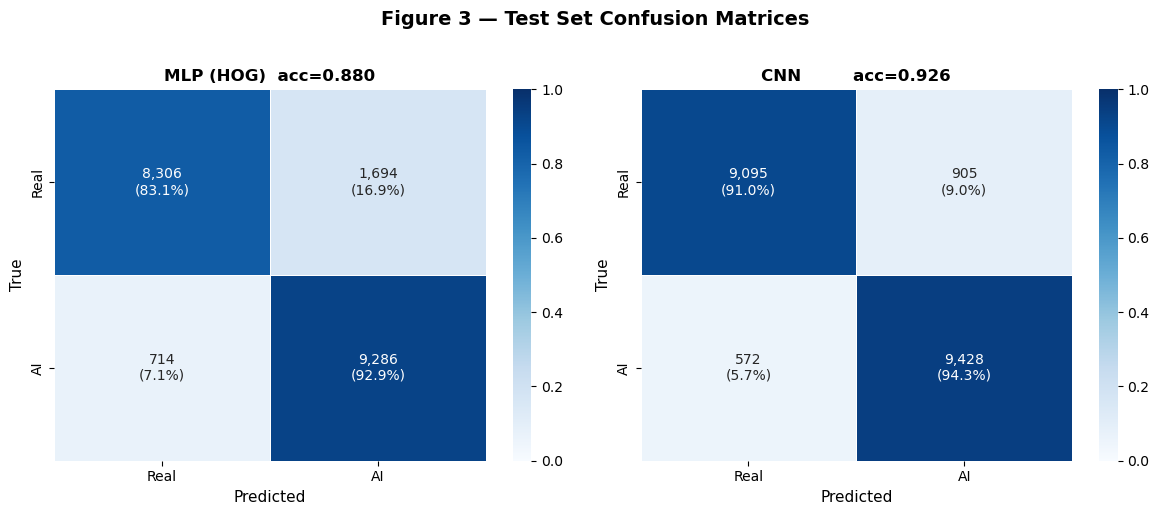

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, preds, true, title in [
    (axes[0], mlp_preds, mlp_true, f'MLP (HOG)  acc={mlp_acc:.3f}'),
    (axes[1], cnn_preds, cnn_true, f'CNN         acc={cnn_acc:.3f}'),
]:
    cm      = confusion_matrix(true, preds)
    # Row-normalise the confusion matrix so each cell shows the fraction
    # of that true class predicted as each label — makes it easier to compare
    # per-class accuracy even when class sizes differ slightly.
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    # Build annotation strings showing both the raw count and the percentage,
    # e.g. '9,823\n(98.2%)' — the count gives scale, the % gives per-class accuracy.
    annot   = np.array([[f'{cm[i,j]:,}\n({cm_norm[i,j]:.1%})'
                         for j in range(2)] for i in range(2)])
    sns.heatmap(
        cm_norm, annot=annot, fmt='', ax=ax,
        xticklabels=['Real', 'AI'], yticklabels=['Real', 'AI'],
        cmap='Blues', vmin=0, vmax=1, linewidths=0.5, linecolor='white'
    )
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('True',      fontsize=11)
    ax.set_title(title,        fontsize=12, fontweight='bold')

fig.suptitle('Figure 3 — Test Set Confusion Matrices', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 11 — Figure 4: Metric comparison bar chart

Replicates Figure 4 from the training notebook, extended with precision and recall.

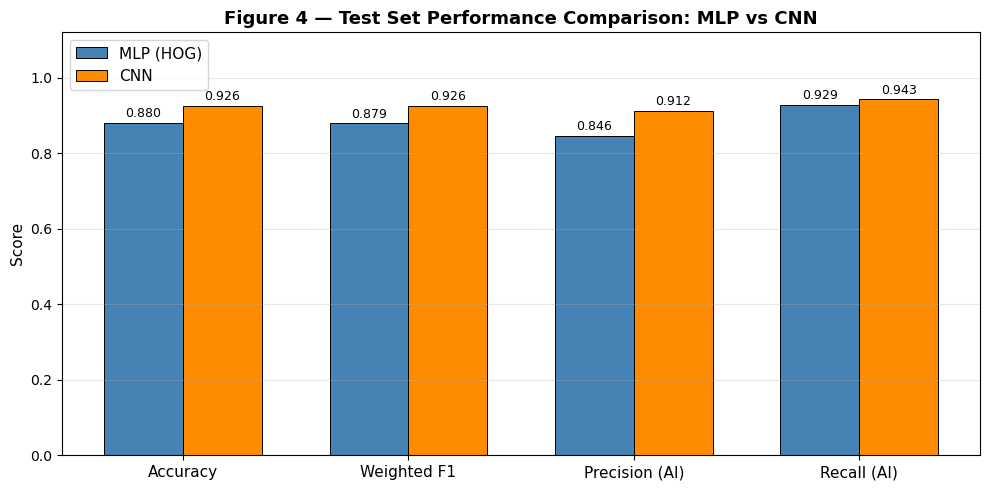

In [11]:
# Precision and Recall are computed only for the AI class (pos_label=1)
# because detecting AI-generated images is the primary task here.
mlp_precision_ai = precision_score(mlp_true, mlp_preds, pos_label=1)
mlp_recall_ai    = recall_score(mlp_true,    mlp_preds, pos_label=1)
cnn_precision_ai = precision_score(cnn_true, cnn_preds, pos_label=1)
cnn_recall_ai    = recall_score(cnn_true,    cnn_preds, pos_label=1)

metric_names = ['Accuracy', 'Weighted F1', 'Precision (AI)', 'Recall (AI)']
mlp_scores   = [mlp_acc, mlp_f1, mlp_precision_ai, mlp_recall_ai]
cnn_scores   = [cnn_acc, cnn_f1, cnn_precision_ai, cnn_recall_ai]

x, width = np.arange(len(metric_names)), 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, mlp_scores, width, label='MLP (HOG)',
               color='steelblue', edgecolor='black', linewidth=0.7)
bars2 = ax.bar(x + width/2, cnn_scores, width, label='CNN',
               color='darkorange', edgecolor='black', linewidth=0.7)

for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.007,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=11)
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0, 1.12)
ax.legend(fontsize=11)
ax.set_title('Figure 4 — Test Set Performance Comparison: MLP vs CNN',
             fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

---
## 12 — ROC curves

ROC curves show the trade-off between true positive rate and false positive rate across
all decision thresholds. AUC is threshold-independent — a perfect classifier scores 1.0.

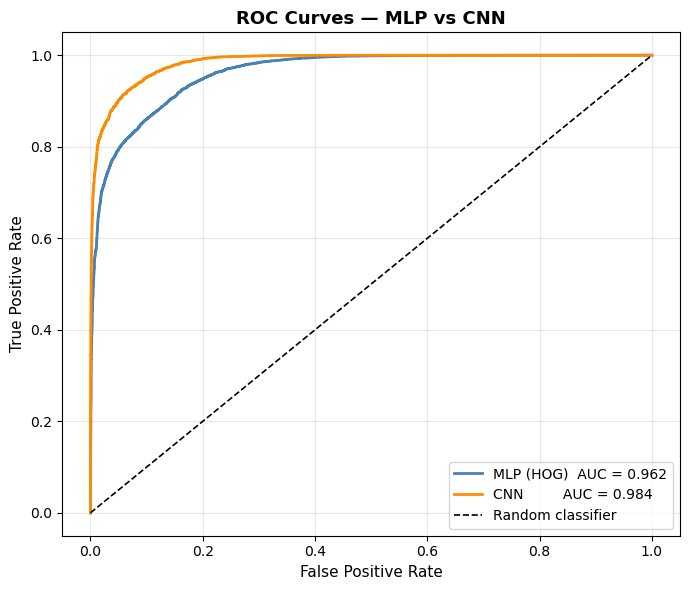

MLP AUC : 0.9616  |  CNN AUC : 0.9843


In [12]:
# roc_curve needs the raw probabilities (mlp_probs / cnn_probs), not the
# hard predictions — it sweeps through all possible decision thresholds internally.
mlp_fpr, mlp_tpr, _ = roc_curve(mlp_true, mlp_probs)
cnn_fpr, cnn_tpr, _ = roc_curve(cnn_true, cnn_probs)
mlp_auc = auc(mlp_fpr, mlp_tpr)
cnn_auc = auc(cnn_fpr, cnn_tpr)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(mlp_fpr, mlp_tpr, lw=2, color='steelblue',
        label=f'MLP (HOG)  AUC = {mlp_auc:.3f}')
ax.plot(cnn_fpr, cnn_tpr, lw=2, color='darkorange',
        label=f'CNN         AUC = {cnn_auc:.3f}')
# The dashed diagonal represents a random classifier (AUC = 0.5).
# A good model's curve should sit well above this line.
ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random classifier')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate',  fontsize=11)
ax.set_title('ROC Curves — MLP vs CNN', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print(f'MLP AUC : {mlp_auc:.4f}  |  CNN AUC : {cnn_auc:.4f}')

---
## 13 — Probability distribution histograms

Shows the distribution of P(AI) scores the models assign to real vs AI images.
A well-separated model pushes real images towards 0 and AI images towards 1 with little overlap.

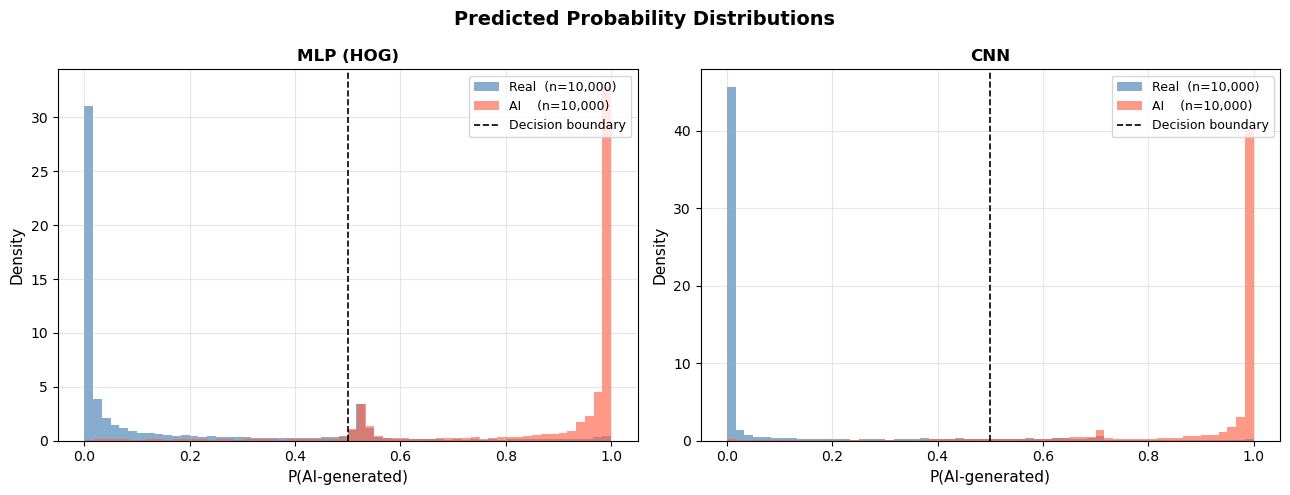

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, probs, true, title in [
    (axes[0], mlp_probs, mlp_true, 'MLP (HOG)'),
    (axes[1], cnn_probs, cnn_true, 'CNN'),
]:
    ax.hist(probs[true == 0], bins=60, alpha=0.65, color='steelblue',
            label=f'Real  (n={int((true==0).sum()):,})', density=True)
    ax.hist(probs[true == 1], bins=60, alpha=0.65, color='tomato',
            label=f'AI    (n={int((true==1).sum()):,})', density=True)
    # The 0.5 line marks the default decision boundary — images above it
    # are classified as AI, images below as real.
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1.2, label='Decision boundary')
    ax.set_xlabel('P(AI-generated)', fontsize=11)
    ax.set_ylabel('Density',         fontsize=11)
    ax.set_title(title,              fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle('Predicted Probability Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 14 — CNN misclassified examples

Replicates Section 8.2 from the training notebook.
Showing a random sample of errors helps identify whether mistakes are on genuinely ambiguous images.

CNN misclassified 1,477 / 20,000 test images (error rate: 7.38%)


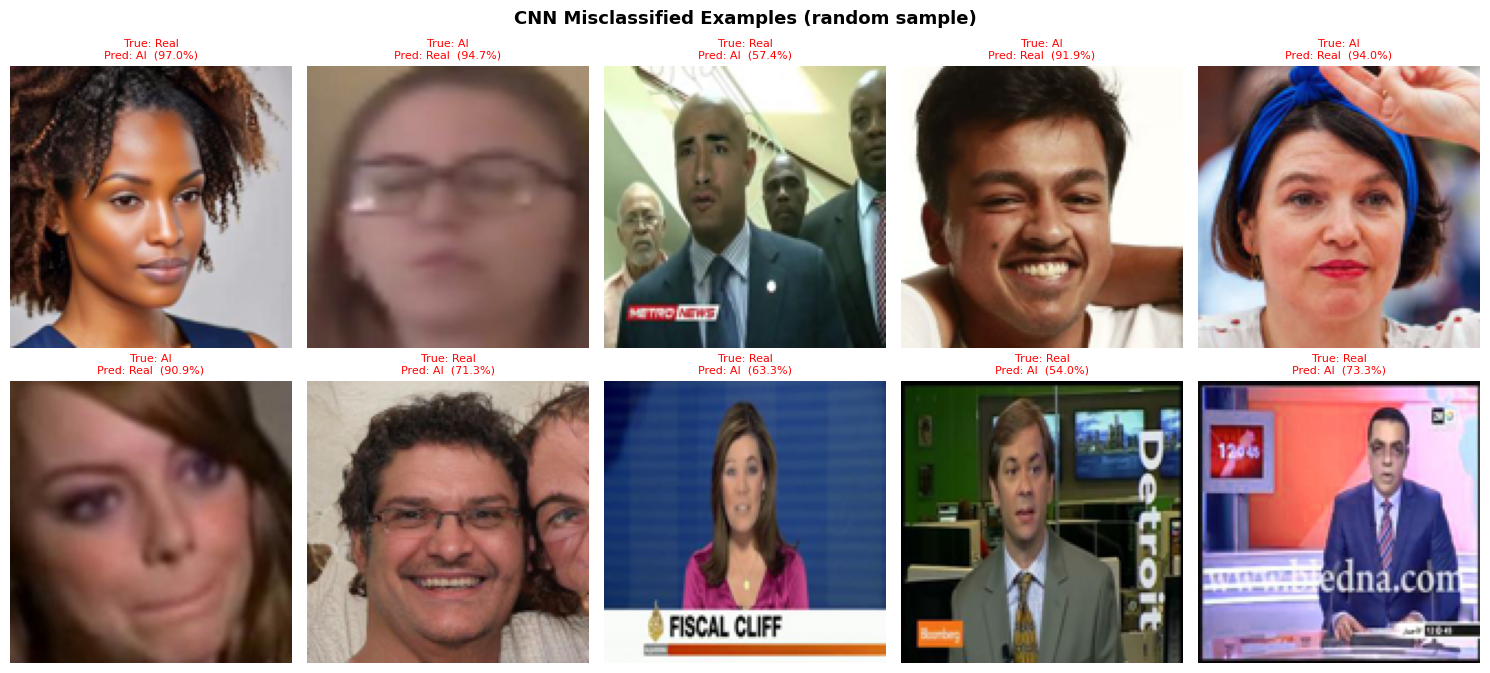

In [14]:
wrong_idx = np.where(cnn_preds != cnn_true)[0]
print(f'CNN misclassified {len(wrong_idx):,} / {len(cnn_true):,} test images '
      f'(error rate: {len(wrong_idx)/len(cnn_true):.2%})')

# Re-seed before sampling so the same 10 examples appear every run,
# making this figure reproducible.
np.random.seed(SEED)
show_idx    = np.random.choice(wrong_idx, size=min(10, len(wrong_idx)), replace=False)
class_names = {0: 'Real', 1: 'AI'}

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, idx in zip(axes.flatten(), show_idx):
    row  = test_df.iloc[idx]
    img  = Image.open(get_full_path(row['filename'])).convert('RGB')
    # conf is the model's confidence in its (wrong) prediction:
    # if it predicted AI, conf = P(AI); if it predicted Real, conf = 1 - P(AI).
    conf = cnn_probs[idx] if cnn_preds[idx] == 1 else 1 - cnn_probs[idx]
    ax.imshow(img.resize((IMG_SIZE, IMG_SIZE)))
    ax.set_title(
        f'True: {class_names[cnn_true[idx]]}\nPred: {class_names[cnn_preds[idx]]}  ({conf:.1%})',
        fontsize=8, color='red'
    )
    ax.axis('off')
for ax in axes.flatten()[len(show_idx):]:
    ax.axis('off')

fig.suptitle('CNN Misclassified Examples (random sample)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 15 — CNN first-layer filter visualisation

Replicates Section 8.1 from the training notebook.
The first conv layer learns low-level detectors — edges, colour gradients, textures.

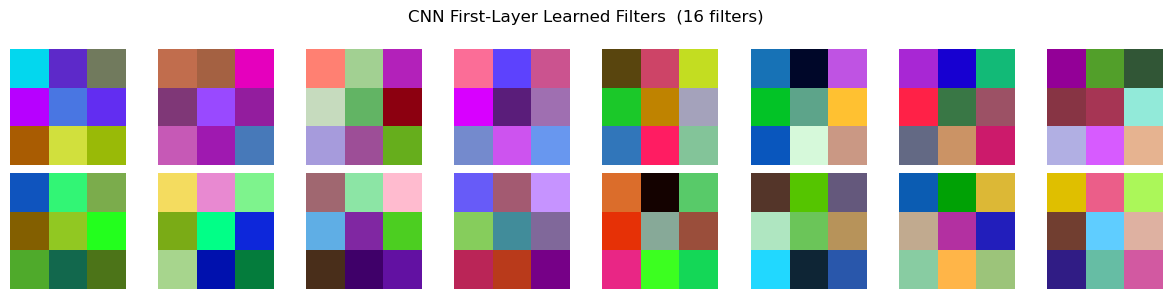

In [15]:
# Visualise the first conv layer's learned filters — these are the low-level
# detectors (edges, colours, textures) the CNN learned to look for.
filters   = cnn_model.features[0].weight.data.cpu()
n_filters = filters.shape[0]
ncols     = 8
nrows     = (n_filters + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.5, nrows * 1.5))
for i, ax in enumerate(axes.flatten()):
    if i < n_filters:
        f = filters[i]
        # Normalise each filter to [0, 1] just for display purposes —
        # this does not affect the actual trained weights.
        f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # normalise to [0, 1] for display
        ax.imshow(f.permute(1, 2, 0).numpy())
    ax.axis('off')

fig.suptitle(f'CNN First-Layer Learned Filters  ({n_filters} filters)', fontsize=12)
plt.tight_layout()
plt.show()

---
## 16 — HOG visualisation on test examples

Shows one correctly-classified real and one correctly-classified AI image alongside their HOG maps —
useful for understanding what the MLP is actually working with.

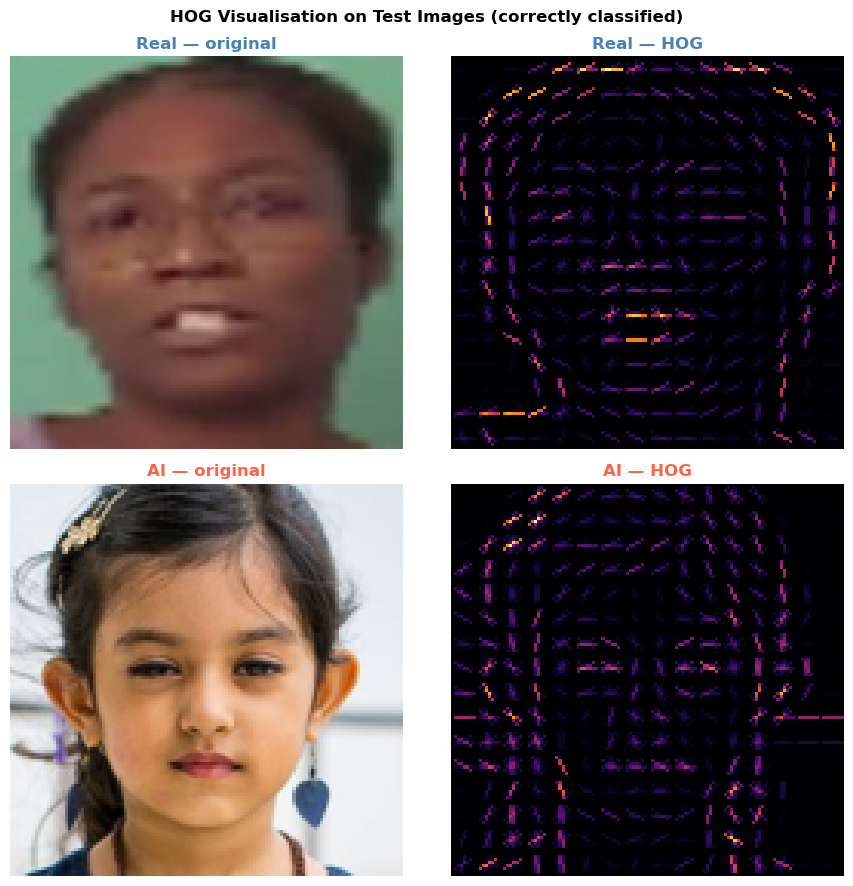

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(9, 9))

for row_idx, (lbl, name, colour) in enumerate([(0, 'Real', 'steelblue'), (1, 'AI', 'tomato')]):
    # Pick a correctly-classified example
    # Only show correctly-classified examples so the HOG map reflects
    # a clean signal for each class rather than an error case.
    correct_mask = (mlp_true == lbl) & (mlp_preds == lbl)
    sample_idx   = np.where(correct_mask)[0][0]
    row          = test_df.iloc[sample_idx]

    img_array = np.array(
        Image.open(get_full_path(row['filename'])).convert('RGB').resize((IMG_SIZE, IMG_SIZE)),
        dtype=np.float32
    ) / 255.0

    # visualize=True returns a rendered HOG gradient image alongside the
    # feature vector. The underscore discards the vector — only the image is needed here.
    _, hog_image = sk_hog(
        img_array, orientations=9,
        pixels_per_cell=(8, 8), cells_per_block=(2, 2),
        channel_axis=-1, visualize=True
    )

    axes[row_idx, 0].imshow(img_array)
    axes[row_idx, 0].set_title(f'{name} — original', color=colour, fontweight='bold')
    axes[row_idx, 0].axis('off')

    axes[row_idx, 1].imshow(hog_image, cmap='inferno')
    axes[row_idx, 1].set_title(f'{name} — HOG', color=colour, fontweight='bold')
    axes[row_idx, 1].axis('off')

fig.suptitle('HOG Visualisation on Test Images (correctly classified)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 17 — Final results summary

Everything in one table — matches the format of Section 9 in the training notebook.

In [17]:
# Collect all metrics into one table for a clean final summary.
# These are the numbers reported in the paper.
summary = pd.DataFrame({
    'Model':            ['MLP (HOG)', 'CNN'],
    'Test Accuracy':    [round(mlp_acc,          4), round(cnn_acc,          4)],
    'Weighted F1':      [round(mlp_f1,            4), round(cnn_f1,            4)],
    'AUC':              [round(mlp_auc,           4), round(cnn_auc,           4)],
    'Precision (AI)':   [round(mlp_precision_ai,  4), round(cnn_precision_ai,  4)],
    'Recall (AI)':      [round(mlp_recall_ai,     4), round(cnn_recall_ai,     4)],
    'Best LR':          [MLP_CFG['lr'],           CNN_CFG['lr']],
    'Best WD':          [MLP_CFG['weight_decay'], CNN_CFG['weight_decay']],
    'Dropout':          [MLP_CFG['dropout'],      CNN_CFG['dropout']],
})

print('=' * 100)
print('FINAL RESULTS SUMMARY')
print('=' * 100)
print(summary.to_string(index=False))


FINAL RESULTS SUMMARY
    Model  Test Accuracy  Weighted F1    AUC  Precision (AI)  Recall (AI)  Best LR  Best WD  Dropout
MLP (HOG)         0.8796       0.8793 0.9616          0.8457       0.9286   0.0005 0.000010      0.5
      CNN         0.9262       0.9261 0.9843          0.9124       0.9428   0.0001 0.000001      0.2
